# MedVault — Encrypted Clinical Records with Cost and Compliance Governance
**BCSE355L Cloud Architecture Design · Team 30 · A2 slot · 24BDS0064**

This notebook reproduces the paper's evaluation. It is a **local simulation, not an AWS deployment**. It compares three methods on the synthetic SCW-64 workload (64 notes, seed 24064):
- **Existing-A**: single-AZ plaintext store
- **Existing-B**: storage-volume encryption only
- **Proposed MedVault**: mock KMS CMK with a key policy, per-record AES-256-GCM data keys (envelope encryption), WAF SQLi rules with parameterised queries, an audit trail, a consent stream, an 80% budget alert (USD 20 cap) and a Multi-AZ failover model

Run all cells in order (Runtime → Run all). The run takes a few seconds.

In [1]:
!pip -q install cryptography matplotlib numpy pandas

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.13/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

## 1. Evaluation harness (`medvault_eval.py`, unchanged from the project archive)

In [2]:
%%writefile medvault_eval.py
#!/usr/bin/env python3
"""
MedVault evaluation harness (local simulation, NOT an AWS deployment).

Implements three methodologies over the same synthetic workload SCW-64:
  Existing-A : single-AZ plaintext relational store, no WAF, no envelope, no audit sink, no budget loop.
  Existing-B : Existing-A + storage (volume) encryption with a single volume key.
  Proposed   : MedVault - mock KMS (CMK wraps per-record AES-256-GCM data keys), key-policy role check,
               WAF regex rule set for SQLi, audit record on every API-path event, DynamoDB-style consent
               table with a stream consumer, 80 % budget alert, and a Multi-AZ failover simulation.

All results are written as CSV files next to this script (results/). Run:  python3 medvault_eval.py
"""
import csv, hashlib, json, os, platform, random, re, sqlite3, statistics, sys, time, urllib.parse, html
from dataclasses import dataclass, field
import cryptography
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.hazmat.backends.openssl.backend import backend as ossl_backend
from cryptography.exceptions import InvalidTag

HERE = os.path.dirname(os.path.abspath(__file__))
OUT = os.path.join(HERE, "results")
os.makedirs(OUT, exist_ok=True)
SEED = 24064            # derived from the register number, fixed for reproducibility
REPS = 100              # timed rounds over the 64 notes (after one warm-up round)

# ----------------------------------------------------------------------------------------------
# 1. Workload SCW-64
# ----------------------------------------------------------------------------------------------
ROLES = ["clinician-readwrite", "random-intern", "auditor-readonly"]
PATIENTS = ["p-24BDS0064"] + [f"p-24BDS0064-{i:02d}" for i in range(1, 16)]

def build_workload():
    rng = random.Random(SEED)
    allergies = ["No penicillin", "Allergic to sulfa drugs", "No known drug allergies", "Latex allergy noted"]
    plans = ["Continue amlodipine 5 mg OD", "Start metformin 500 mg BD", "Review HbA1c in 3 months",
             "Refer to physiotherapy", "Repeat lipid profile", "Advise low-salt diet",
             "Taper prednisolone over 2 weeks", "Order chest X-ray"]
    notes = [("enc-%06d" % 0, PATIENTS[0], "BP 120/80. No penicillin. Follow-up in 14 days.")]  # console seed
    for i in range(1, 64):
        sys_bp, dia = rng.randint(104, 168), rng.randint(64, 102)
        hr = rng.randint(58, 108)
        note = (f"BP {sys_bp}/{dia}. HR {hr}. {rng.choice(allergies)}. {rng.choice(plans)}. "
                f"Follow-up in {rng.choice([7, 10, 14, 21, 28, 30])} days. Ref {i:02d}.")
        notes.append(("enc-%06d" % i, PATIENTS[i % 16], note))
    return notes

SQLI = [  # 8 canonical payloads (string context of a patient_id lookup)
    ("S1-tautology-quoted", "' OR '1'='1"),
    ("S2-tautology-comment", "' OR 1=1 --"),
    ("S3-stacked-drop", "'; DROP TABLE encounter; --"),
    ("S4-union-schema", "' UNION SELECT name, sql FROM sqlite_master --"),
    ("S5-comment-truncation", "p-24BDS0064' --"),
    ("S6-boolean-subquery", "' AND 1=(SELECT COUNT(*) FROM encounter) --"),
    ("S7-time-based", "' OR SLEEP(5) --"),
    ("S8-stacked-exec", "'; EXEC xp_cmdshell('dir'); --"),
]
BENIGN = [  # 24 legitimate lookups / searches, some deliberately SQL-looking
    "p-24BDS0064", "p-24BDS0064-03", "p-24BDS0064-07", "p-24BDS0064-15", "enc-000017", "enc-000042",
    "Follow-up in 14 days", "BP 120/80", "No penicillin", "O'Brien", "D'Souza", "select clinic A",
    "drop-in review", "1 or 2 tablets at night", "HbA1c 7.1%", "update allergy list",
    "union territory Puducherry", "pain score 3/10", "insulin 10 units", "and/or dietary advice",
    "review - see previous note", "Mother's history: diabetes", "BP = 130/85", "ward 4; bed 12",
]
EVASION = [  # out-of-scope probe: obfuscated payloads (not part of the 8 canonical strings)
    ("E1-mixed-case", "' oR 'a'='a"),
    ("E2-url-encoded", "%27%20OR%201%3D1--"),
    ("E3-inline-comment", "' UN/**/ION SEL/**/ECT encounter_id, patient_id FROM encounter WHERE ''='"),
    ("E4-json-operator", "' OR '{\"a\":1}'::jsonb @> '{\"a\":1}'::jsonb OR ''='"),
]

# ----------------------------------------------------------------------------------------------
# 2. Shared building blocks
# ----------------------------------------------------------------------------------------------
class AccessDenied(Exception):
    pass

def new_db():
    c = sqlite3.connect(":memory:")
    c.execute("CREATE TABLE encounter (encounter_id TEXT PRIMARY KEY, patient_id TEXT, body BLOB, "
              "edk BLOB, nonce BLOB, ct_sha256 TEXT, s3_pointer TEXT, writer_az TEXT)")
    return c

WAF_RULES = [  # MedVault-SQLi rule set (local regex analogue of a managed SQLi rule group)
    ("tautology_quoted", re.compile(r"'\s*(or|and)\s+'?\w+'?\s*=\s*'?\w+", re.I)),
    ("tautology_numeric", re.compile(r"\b(or|and)\s+(\d+)\s*=\s*\2\b", re.I)),
    ("quote_comment", re.compile(r"'\s*(--|#|/\*)")),
    ("union_select", re.compile(r"\bunion\b(\s+all)?\s+select\b", re.I)),
    ("stacked_statement", re.compile(r";\s*(drop|delete|insert|update|alter|create|exec|execute|shutdown|truncate)\b", re.I)),
    ("time_based", re.compile(r"\b(sleep|benchmark|pg_sleep)\s*\(|waitfor\s+delay", re.I)),
    ("dangerous_objects", re.compile(r"\bxp_cmdshell\b|@@version|\binformation_schema\b|\bsqlite_master\b", re.I)),
    ("quote_subquery", re.compile(r"'\s*(and|or)\s*\d*\s*=?\s*\(\s*select\b", re.I)),
]

def waf_inspect(value):
    """Text transformations (URL decode, HTML-entity decode, whitespace compression) then rule match."""
    v = html.unescape(urllib.parse.unquote_plus(value))
    v = re.sub(r"\s+", " ", v)
    for name, rx in WAF_RULES:
        if rx.search(v):
            return name
    return None

def pctl(xs, p):
    s = sorted(xs); k = (len(s) - 1) * p / 100.0
    f = int(k); c = min(f + 1, len(s) - 1)
    return s[f] + (s[c] - s[f]) * (k - f)

# ----------------------------------------------------------------------------------------------
# 3. Methodologies
# ----------------------------------------------------------------------------------------------
class ExistingA:
    name = "Existing-A"
    label = "Existing-A (single-AZ plaintext)"
    def __init__(self):
        self.db = new_db(); self.audit = []; self.writer_az = "ap-south-1a"
    def api_write(self, role, enc, patient, note):
        self.db.execute("INSERT OR REPLACE INTO encounter (encounter_id, patient_id, body, writer_az) VALUES (?,?,?,?)",
                        (enc, patient, note.encode(), self.writer_az))
    def api_read(self, role, enc):
        r = self.db.execute("SELECT body FROM encounter WHERE encounter_id=?", (enc,)).fetchone()
        return r[0].decode()
    def db_principal_read(self, role, enc):     # principal with read access to the database tier
        return self.api_read(role, enc)
    def disk_image(self):
        return self.db.serialize()
    def engine_view(self):
        rows = self.db.execute("SELECT * FROM encounter").fetchall()
        return repr(rows).encode() + b"".join(r[2] or b"" for r in rows)
    def search(self, value):                     # naive string-concatenated query, no WAF
        q = "SELECT encounter_id, patient_id FROM encounter WHERE patient_id = '" + value + "'"
        return {"reached_compute": True, "blocked_by": None, **run_sql(self.db, q)}
    def tamper(self, enc):
        self.db.execute("UPDATE encounter SET body = ? WHERE encounter_id = ?", (b"BP 90/60. Discharge today.", enc))
    def read_detects_tamper(self, enc):
        try:
            self.api_read("clinician-readwrite", enc); return False
        except Exception:
            return True

class ExistingB(ExistingA):
    name = "Existing-B"
    label = "Existing-B (storage encryption only)"
    def __init__(self):
        super().__init__(); self.volume_key = AESGCM.generate_key(256)
    def disk_image(self):                         # the storage layer encrypts every page with one volume key
        n = os.urandom(12)
        return n + AESGCM(self.volume_key).encrypt(n, self.db.serialize(), None)

def run_sql(db, q):
    try:
        rows = db.execute(q).fetchall()
        return {"outcome": f"executed; {len(rows)} rows", "rows": len(rows)}
    except Exception as e:
        return {"outcome": f"DB error: {type(e).__name__}", "rows": 0}

class MockKMS:
    """CMK never leaves this object. Key policy is evaluated on every call; every call is logged."""
    def __init__(self, trail):
        self._cmk = AESGCM(AESGCM.generate_key(256))
        self.policy = {"GenerateDataKey": {"clinician-readwrite"}, "Decrypt": {"clinician-readwrite"}}
        self.trail = trail
    def generate_data_key(self, principal, context):
        if principal not in self.policy["GenerateDataKey"]:
            self.trail.append(("KMS.GenerateDataKey.Denied", principal, context)); raise AccessDenied("GenerateDataKey")
        dk = AESGCM.generate_key(256); n = os.urandom(12)
        edk = n + self._cmk.encrypt(n, dk, context)
        self.trail.append(("KMS.GenerateDataKey", principal, context))
        return dk, edk
    def decrypt(self, principal, edk, context):
        if principal not in self.policy["Decrypt"]:
            self.trail.append(("KMS.Decrypt.Denied", principal, context)); raise AccessDenied("Decrypt")
        dk = self._cmk.decrypt(edk[:12], edk[12:], context)   # raises InvalidTag on wrong context
        self.trail.append(("KMS.Decrypt", principal, context))
        return dk

class Proposed:
    name = "Proposed"
    label = "Proposed MedVault"
    CAP = 20.0
    def __init__(self, timers=None):
        self.db = new_db(); self.trail = []; self.kms = MockKMS(self.trail)
        self.s3 = {}; self.consent = {}; self.stream = []; self.sns = []; self.sfn = []
        self.metrics = {}; self.volume_key = AESGCM.generate_key(256); self.writer_az = "ap-south-1a"
        self.spend = 0.0; self.alerts = []; self.timers = timers
    def _t(self, key, t0):
        if self.timers is not None:
            self.timers.setdefault(key, []).append((time.perf_counter_ns() - t0) / 1000.0)
    def _metric(self, name):
        self.metrics[name] = self.metrics.get(name, 0) + 1
    def govern(self, event, principal, obj, usd=0.0):
        self.trail.append((event, principal, obj)); self._metric(event)
        if usd:
            before = self.spend; self.spend += usd
            if before < 0.8 * self.CAP <= self.spend:
                self.alerts.append(("Budgets.Alert80", self.spend)); self.trail.append(("Budgets.Alert80", "billing", f"{self.spend:.2f}"))
    def api_write(self, role, enc, patient, note):
        t0 = time.perf_counter_ns()
        blocked = waf_inspect(enc) or waf_inspect(patient)
        self._t("1 WAF inspection", t0)
        if blocked:
            self.govern("WAF.Block", role, enc); raise AccessDenied("WAF")
        ctx = f"{enc}|{patient}".encode()
        t0 = time.perf_counter_ns()
        try:
            dk, edk = self.kms.generate_data_key(role, ctx)
        except AccessDenied:
            self.govern("PutRecord.Denied", role, enc); raise
        self._t("2 GenerateDataKey (mock KMS)", t0)
        t0 = time.perf_counter_ns()
        n = os.urandom(12); ct = AESGCM(dk).encrypt(n, note.encode(), ctx); del dk
        self._t("3 AES-256-GCM encrypt", t0)
        t0 = time.perf_counter_ns()
        ptr = f"s3://medvault-cipher/{enc}.bin"; self.s3[ptr] = ct
        self.db.execute("INSERT OR REPLACE INTO encounter (encounter_id, patient_id, body, edk, nonce, ct_sha256, s3_pointer, writer_az)"
                        " VALUES (?,?,?,?,?,?,?,?)", (enc, patient, None, edk, n, hashlib.sha256(ct).hexdigest(), ptr, self.writer_az))
        self.consent[patient] = {"consent": True, "session": "hot"}
        self.stream.append({"eventName": "MODIFY", "keys": {"patient_id": patient}, "new": dict(self.consent[patient])})
        self._t("4 Persist (Aurora row + S3 object + consent item)", t0)
        t0 = time.perf_counter_ns()
        self.govern("PutRecord", role, enc, usd=0.0)
        self._t("5 Audit + metric", t0)
    def consume_stream(self):
        n = 0
        while self.stream:
            rec = self.stream.pop(0)
            self.trail.append(("Stream.Audit", "stream-consumer", rec["keys"]["patient_id"]))
            self.sns.append(("ClinicianNotify", rec["keys"]["patient_id"]))
            self.sfn.append(("Retention", rec["keys"]["patient_id"])); n += 1
        return n
    def _fetch(self, enc):
        return self.db.execute("SELECT patient_id, edk, nonce, s3_pointer, ct_sha256 FROM encounter WHERE encounter_id=?", (enc,)).fetchone()
    def api_read(self, role, enc):
        if waf_inspect(enc):
            self.govern("WAF.Block", role, enc); raise AccessDenied("WAF")
        patient, edk, n, ptr, h = self._fetch(enc)
        if not self.consent.get(patient, {}).get("consent"):
            self.govern("Read.Denied.Consent", role, enc); raise AccessDenied("consent")
        ctx = f"{enc}|{patient}".encode()
        try:
            dk = self.kms.decrypt(role, edk, ctx)
        except AccessDenied:
            self.govern("KMS.Decrypt.Denied", role, enc); raise
        pt = AESGCM(dk).decrypt(n, self.s3[ptr], ctx); del dk
        self.govern("KMS.Decrypt", role, enc)
        return pt.decode()
    def db_principal_read(self, role, enc):
        """A principal with database read access still only sees EDK + ciphertext; plaintext needs kms:Decrypt."""
        patient, edk, n, ptr, h = self._fetch(enc)
        dk = self.kms.decrypt(role, edk, f"{enc}|{patient}".encode())   # raises AccessDenied for intern/auditor
        return AESGCM(dk).decrypt(n, self.s3[ptr], f"{enc}|{patient}".encode()).decode()
    def disk_image(self):
        blob = self.db.serialize() + b"".join(self.s3.values())
        n = os.urandom(12)
        return n + AESGCM(self.volume_key).encrypt(n, blob, None)
    def engine_view(self):
        rows = self.db.execute("SELECT * FROM encounter").fetchall()
        return (repr(rows).encode() + b"".join(self.s3.values()) + json.dumps(self.consent).encode()
                + repr(self.trail).encode() + repr(self.sns).encode() + repr(self.sfn).encode())
    def search(self, value):
        rule = waf_inspect(value)
        if rule:
            self.govern("WAF.Block", "anonymous", value[:24])
            return {"reached_compute": False, "blocked_by": rule, "outcome": "blocked at WAF", "rows": 0}
        rows = self.db.execute("SELECT encounter_id, patient_id FROM encounter WHERE patient_id = ?", (value,)).fetchall()
        self.govern("Search", "clinician-readwrite", value[:24])
        return {"reached_compute": True, "blocked_by": None, "outcome": f"executed (parameterised); {len(rows)} rows", "rows": len(rows)}
    def tamper(self, enc):
        ptr = self._fetch(enc)[3]; ct = bytearray(self.s3[ptr]); ct[0] ^= 0x01; self.s3[ptr] = bytes(ct)
    def read_detects_tamper(self, enc):
        try:
            self.api_read("clinician-readwrite", enc); return False
        except InvalidTag:
            self.govern("Integrity.Fail", "clinician-readwrite", enc); return True

# ----------------------------------------------------------------------------------------------
# 4. Experiments
# ----------------------------------------------------------------------------------------------
def write_csv(name, header, rows):
    with open(os.path.join(OUT, name), "w", newline="") as f:
        w = csv.writer(f); w.writerow(header); w.writerows(rows)

def enforcement(notes):
    rows, traces, acc_rows = [], [], []
    for M in (ExistingA, ExistingB, Proposed):
        m = M()
        for enc, pat, note in notes:
            m.api_write("clinician-readwrite", enc, pat, note)
        img, view = m.disk_image(), m.engine_view()
        absent_disk = sum(note.encode() not in img and note[:12].encode() not in img for _, _, note in notes)
        absent_view = sum(note.encode() not in view and note[:12].encode() not in view for _, _, note in notes)
        auth_ok = sum(m.api_read("clinician-readwrite", enc) == note for enc, _, note in notes)
        blocked = 0; attempts = 0
        for role in ("random-intern", "auditor-readonly"):
            for enc, _, note in notes:
                attempts += 1
                try:
                    got = m.db_principal_read(role, enc)
                    blocked += (got != note)
                except AccessDenied:
                    blocked += 1
        if isinstance(m, Proposed):
            for role in ("random-intern", "auditor-readonly"):      # API path as well, so it is audited
                for enc, _, _ in notes:
                    try: m.api_read(role, enc)
                    except AccessDenied: pass
        wdeny = 0
        for role in ("random-intern", "auditor-readonly"):         # unauthorised writes (overwrite attempts)
            for enc, pat, note in notes:
                try:
                    m.api_write(role, enc, pat, "FORGED: " + note)
                    wdeny += (m.api_read("clinician-readwrite", enc) == note)   # accepted -> record overwritten
                    m.api_write("clinician-readwrite", enc, pat, note)          # restore for the next checks
                except AccessDenied:
                    wdeny += 1
        sqli_blocked = sum(not m.search(p)["reached_compute"] for _, p in SQLI)
        evasion_blocked = sum(not m.search(p)["reached_compute"] for _, p in EVASION)
        fp = sum(not m.search(b)["reached_compute"] for b in BENIGN)
        # audit coverage over API-path events: 64 writes + 128 denied writes + 64 authorised reads + 128 denied reads + 8 SQLi
        if isinstance(m, Proposed):
            ev = [e[0] for e in m.trail]
            logged = (min(ev.count("PutRecord"), 64) + min(ev.count("PutRecord.Denied"), 128) + min(ev.count("KMS.Decrypt"), 64)
                      + min(ev.count("KMS.Decrypt.Denied"), 128) + min(ev.count("WAF.Block"), 8))
        else:
            logged = len(m.audit)
        audit_total = 64 + 128 + 64 + 128 + 8   # writes, denied writes, reads, denied reads, SQLi
        # integrity: tamper every record then read it back
        det = 0
        for enc, _, _ in notes:
            m.tamper(enc); det += m.read_detects_tamper(enc)
        rows += [
            (m.name, "Plaintext absent from raw storage image", absent_disk, 64),
            (m.name, "Plaintext absent from database-engine view", absent_view, 64),
            (m.name, "Authorised read returns correct note", auth_ok, 64),
            (m.name, "Unauthorised plaintext access blocked", blocked, attempts),
            (m.name, "SQLi blocked before compute", sqli_blocked, len(SQLI)),
            (m.name, "Benign requests wrongly blocked (false positives)", fp, len(BENIGN)),
            (m.name, "Audit coverage of API-path events", logged, audit_total),
            (m.name, "Tampered records detected on read", det, 64),
            (m.name, "Unauthorised writes denied", wdeny, 128),
            (m.name, "Evasion probes blocked at WAF (out-of-scope)", evasion_blocked, len(EVASION)),
        ]
        # decision accuracy: must-block cases (128 unauthorised reads, 128 unauthorised writes, 8 SQLi, 64 tampered reads)
        # and must-allow cases (64 authorised writes, 64 authorised reads, 24 benign requests)
        tp = blocked + wdeny + sqli_blocked + det; tn = 64 + auth_ok + (len(BENIGN) - fp)
        acc_rows.append((m.name, "SCW-64 (480 cases)", tp, 328, tn, 152, round(100 * (tp + tn) / 480, 2)))
        acc_rows.append((m.name, "SCW-64 + 4 evasion probes (484 cases)", tp + evasion_blocked, 332, tn, 152,
                         round(100 * (tp + evasion_blocked + tn) / 484, 2)))
    write_csv("decision_accuracy.csv", ["method", "case_set", "correctly_blocked", "must_block", "correctly_allowed", "must_allow", "accuracy_pct"], acc_rows)
    write_csv("enforcement_summary.csv", ["method", "metric", "count", "total", "rate_pct"],
              [(a, b, c, d, round(100.0 * c / d, 2)) for a, b, c, d in rows])
    return rows

def waf_detail():
    out = []
    for M in (ExistingA, ExistingB, Proposed):
        m = M()
        for enc, pat, note in build_workload():
            m.api_write("clinician-readwrite", enc, pat, note)
        for kind, items in (("SQLi", SQLI), ("benign", [(f"B{i+1:02d}", b) for i, b in enumerate(BENIGN)]), ("evasion-probe", EVASION)):
            for pid, payload in items:
                r = m.search(payload)
                out.append((m.name, kind, pid, payload, "no" if r["reached_compute"] else "yes", r["blocked_by"] or "-", r["outcome"]))
    write_csv("waf_requests.csv", ["method", "kind", "id", "request_value", "blocked_before_compute", "matched_rule", "outcome"], out)
    return out

def streams_check(notes):
    m = Proposed()
    for enc, pat, note in notes:
        m.api_write("clinician-readwrite", enc, pat, note)
    produced = len(m.stream)
    stream_blob = json.dumps(m.stream).encode()
    leak = sum(note.encode() in stream_blob or note[:12].encode() in stream_blob for _, _, note in notes)
    consumed = m.consume_stream()
    rows = [("stream records produced", produced), ("stream records consumed", consumed),
            ("SNS notifications published", len(m.sns)), ("Step Functions executions started", len(m.sfn)),
            ("stream records containing note plaintext", leak),
            ("distinct patients in consent table", len(m.consent))]
    write_csv("streams_integration.csv", ["quantity", "value"], rows)
    return rows

def failover(notes):
    """Discrete-event simulation on a simulated clock (not wall time). One write every 10 s; AZ-a is lost at t = 400 s.
    Proposed: cluster volume = 6 storage copies, 2 per AZ (ap-south-1a/b/c); write quorum 4/6, read quorum 3/6.
    Writer fails over to the tier-0 reader in ap-south-1b; promotion window modelled as 30 s (AWS: typically <60 s, often <30 s).
    Existing-A/B: single-AZ instance; recovery by point-in-time restore; logs shipped every 300 s (AWS RDS documentation)."""
    FAIL_T, PROMO, LOG_EVERY = 400, 30, 300
    rows = []
    for name in ("Existing-A", "Existing-B", "Proposed"):
        nodes = {f"{az}-{k}": [] for az in ("ap-south-1a", "ap-south-1b", "ap-south-1c") for k in (1, 2)}
        writer = "ap-south-1a"; committed = []; retried = 0; rejected_no_writer = 0
        m = Proposed() if name == "Proposed" else None
        for i, (enc, pat, note) in enumerate(notes):
            t = (i + 1) * 10
            if name == "Proposed":
                if t >= FAIL_T:
                    for k in list(nodes):
                        if k.startswith("ap-south-1a"): nodes.pop(k, None)
                    writer = "ap-south-1b"
                    if t < FAIL_T + PROMO:
                        retried += 1                      # write fails with an exception, client retries after promotion
                m.writer_az = writer
                m.api_write("clinician-readwrite", enc, pat, note)
                live = list(nodes)
                if len(live) >= 4:
                    for k in live: nodes[k].append(enc)
                committed.append((t, enc))
            else:
                if t >= FAIL_T:
                    rejected_no_writer += 1; continue     # no standby: writer gone until a manual restore
                committed.append((t, enc))
        if name == "Proposed":
            surv = {enc for enc in (e for _, e in committed) if sum(enc in v for v in nodes.values()) >= 3}
            lost = len(committed) - len(surv)
            readable = sum(m.api_read("clinician-readwrite", enc) == note for enc, _, note in notes)
            rows.append((name, len(committed), lost, retried, 0, "yes (tier-0 reader in ap-south-1b promoted)", writer, readable))
        else:
            last_log = (FAIL_T // LOG_EVERY) * LOG_EVERY
            lost = sum(1 for t, _ in committed if t > last_log)
            rows.append((name, len(committed), lost, 0, rejected_no_writer, "no (manual point-in-time restore)", "none until restore", len(committed) - lost))
    write_csv("failover.csv", ["method", "writes_committed_before_or_after_failure", "committed_writes_lost", "writes_retried_during_promotion",
                               "writes_rejected_no_writer", "automatic_writer_recovery", "writer_after_event", "records_recoverable"], rows)
    return rows

def budget():
    """Synthetic 30-day lab month, USD 20 cap. Daily cost: 0.40 base; a search reader left running from day 10 adds 0.42/day.
    Forecast = month-to-date + mean(last 7 days) * remaining days. Only the Proposed loop evaluates thresholds."""
    cap, rows, alert_forecast, alert_actual, breach = 20.0, [], None, None, None
    mtd, daily = 0.0, []
    for d in range(1, 31):
        c = 0.40 + (0.42 if d >= 10 else 0.0)
        daily.append(c); mtd += c
        fc = mtd + (sum(daily[-7:]) / len(daily[-7:])) * (30 - d)
        if alert_forecast is None and fc >= 0.8 * cap: alert_forecast = d
        if alert_actual is None and mtd >= 0.8 * cap: alert_actual = d
        if breach is None and mtd >= cap: breach = d
        rows.append((d, round(c, 2), round(mtd, 2), round(fc, 2)))
    write_csv("budget_trace.csv", ["day", "daily_cost_usd", "month_to_date_usd", "linear_forecast_usd"], rows)
    summ = [("Existing-A", "none", "none", breach), ("Existing-B", "none", "none", breach),
            ("Proposed", alert_forecast, alert_actual, breach)]
    write_csv("budget_summary.csv", ["method", "forecast_80pct_alert_day", "actual_80pct_alert_day", "day_cap_breached"], summ)
    return rows, summ

def operator_traces(enf):
    get = {(a, b): (c, d) for a, b, c, d in enf}
    fo = {r[0]: r for r in failover(build_workload())}
    _, bsum = budget()
    out = []
    for name in ("Existing-A", "Existing-B", "Proposed"):
        t1 = get[(name, "Plaintext absent from database-engine view")][0] == 64
        t2 = get[(name, "Authorised read returns correct note")][0] == 64
        t3 = get[(name, "Unauthorised plaintext access blocked")][0] == 128
        t4 = get[(name, "SQLi blocked before compute")][0] == 8
        t5 = fo[name][2] == 0 and fo[name][5].startswith("yes")
        t6 = [b for b in bsum if b[0] == name][0][1] != "none"
        for tid, desc, ok in (("T1", "Write encrypted record: no plaintext in stored row", t1), ("T2", "Authorised read returns note", t2),
                              ("T3", "Intern read denied", t3), ("T4", "SQLi stopped before compute", t4),
                              ("T5", "Writer-AZ loss: no committed record lost, automatic recovery", t5),
                              ("T6", "Spend crosses 80 %: alert raised", t6)):
            out.append((name, tid, desc, "pass" if ok else "fail"))
    write_csv("operator_traces.csv", ["method", "trace", "observable", "result"], out)
    return out

def latency(notes):
    raw, summary = [], []
    breakdown = {}
    for M in (ExistingA, ExistingB, Proposed):
        samples = {"write": [], "authorised read": [], "denied read": []}
        for rnd in range(REPS + 1):
            m = M(timers=breakdown if (M is Proposed and rnd > 0) else None) if M is Proposed else M()
            for enc, pat, note in notes:
                t0 = time.perf_counter_ns(); m.api_write("clinician-readwrite", enc, pat, note); t1 = time.perf_counter_ns()
                if rnd: samples["write"].append((t1 - t0) / 1000.0)
            for enc, pat, note in notes:
                t0 = time.perf_counter_ns(); m.api_read("clinician-readwrite", enc); t1 = time.perf_counter_ns()
                if rnd: samples["authorised read"].append((t1 - t0) / 1000.0)
            if M is Proposed:
                for enc, pat, note in notes:
                    t0 = time.perf_counter_ns()
                    try: m.api_read("random-intern", enc)
                    except AccessDenied: pass
                    t1 = time.perf_counter_ns()
                    if rnd: samples["denied read"].append((t1 - t0) / 1000.0)
        for op, xs in samples.items():
            if not xs:
                summary.append((M.name, op, 0, "n/a", "n/a", "n/a", "n/a")); continue
            for i, x in enumerate(xs): raw.append((M.name, op, i // 64 + 1, i % 64, round(x, 3)))
            summary.append((M.name, op, len(xs), round(statistics.mean(xs), 2), round(statistics.median(xs), 2),
                            round(pctl(xs, 95), 2), round(statistics.stdev(xs), 2)))
    write_csv("latency_raw.csv", ["method", "operation", "round", "note_index", "latency_us"], raw)
    write_csv("latency_summary.csv", ["method", "operation", "n", "mean_us", "median_us", "p95_us", "stdev_us"], summary)
    brow = [(k, len(v), round(statistics.mean(v), 2), round(pctl(v, 95), 2)) for k, v in sorted(breakdown.items())]
    write_csv("proposed_write_breakdown.csv", ["component", "n", "mean_us", "p95_us"], brow)
    return summary, brow

def environment():
    cpu = "unknown"
    try:
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"): cpu = line.split(":", 1)[1].strip(); break
    except OSError: pass
    env = {"cpu": cpu, "logical_cpus": os.cpu_count(), "os": platform.platform(), "python": platform.python_version(),
           "cryptography": cryptography.__version__, "openssl": ossl_backend.openssl_version_text(),
           "sqlite": sqlite3.sqlite_version, "reps": REPS, "seed": SEED,
           "run_at_local": time.strftime("%Y-%m-%d %H:%M:%S %Z")}
    with open(os.path.join(OUT, "environment.json"), "w") as f: json.dump(env, f, indent=2)
    return env

if __name__ == "__main__":
    notes = build_workload()
    write_csv("workload_scw64.csv", ["encounter_id", "patient_id", "synthetic_note"], notes)
    env = environment(); print(json.dumps(env, indent=2))
    enf = enforcement(notes)
    for r in enf: print(f"{r[0]:11s} {r[1]:52s} {r[2]:4d}/{r[3]:<4d} {100*r[2]/r[3]:6.1f}%")
    waf_detail()
    print(streams_check(notes))
    print(failover(notes))
    print(budget()[1])
    for r in operator_traces(enf): print(r)
    s, b = latency(notes)
    for r in s: print(r)
    for r in b: print(r)


Overwriting medvault_eval.py


In [3]:
!python3 medvault_eval.py

{
  "cpu": "Intel(R) Xeon(R) Processor",
  "logical_cpus": 8,
  "os": "Linux-6.12.94+-x86_64-with-glibc2.41",
  "python": "3.13.5",
  "cryptography": "43.0.0",
  "openssl": "OpenSSL 3.5.7 9 Jun 2026",
  "sqlite": "3.46.1",
  "reps": 100,
  "seed": 24064,
  "run_at_local": "2026-11-03 17:46:39 IST"
}


Existing-A  Plaintext absent from raw storage image                 0/64      0.0%
Existing-A  Plaintext absent from database-engine view              0/64      0.0%
Existing-A  Authorised read returns correct note                   64/64    100.0%
Existing-A  Unauthorised plaintext access blocked                   0/128     0.0%
Existing-A  SQLi blocked before compute                             0/8       0.0%
Existing-A  Benign requests wrongly blocked (false positives)       0/24      0.0%
Existing-A  Audit coverage of API-path events                       0/392     0.0%
Existing-A  Tampered records detected on read                       0/64      0.0%
Existing-A  Unauthorised writes denied                              0/128     0.0%
Existing-A  Evasion probes blocked at WAF (out-of-scope)            0/4       0.0%
Existing-B  Plaintext absent from raw storage image                64/64    100.0%
Existing-B  Plaintext absent from database-engine view              0/64      0.0%
Exis

('Existing-A', 'write', 6400, 1.83, 1.26, 2.76, 6.63)
('Existing-A', 'authorised read', 6400, 1.95, 1.32, 2.47, 15.4)
('Existing-A', 'denied read', 0, 'n/a', 'n/a', 'n/a', 'n/a')
('Existing-B', 'write', 6400, 1.55, 1.24, 1.82, 5.36)
('Existing-B', 'authorised read', 6400, 1.57, 1.29, 1.66, 5.42)
('Existing-B', 'denied read', 0, 'n/a', 'n/a', 'n/a', 'n/a')
('Proposed', 'write', 6400, 16.86, 14.51, 27.64, 14.23)
('Proposed', 'authorised read', 6400, 10.58, 9.73, 13.81, 4.79)
('Proposed', 'denied read', 6400, 5.3, 4.75, 6.93, 15.21)
('1 WAF inspection', 6400, 4.9, 6.36)
('2 GenerateDataKey (mock KMS)', 6400, 3.05, 5.0)
('3 AES-256-GCM encrypt', 6400, 3.75, 5.11)
('4 Persist (Aurora row + S3 object + consent item)', 6400, 3.67, 5.9)
('5 Audit + metric', 6400, 0.32, 0.51)


## 2. Figure script (`make_figs.py`). Every graph is drawn from `results/*.csv`; no number is typed in by hand

In [4]:
%%writefile make_figs.py
#!/usr/bin/env python3
"""Draws the paper's graphs from the CSV files in results/ (no numbers are typed in by hand)."""
import csv, os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
HERE = os.path.dirname(os.path.abspath(__file__)); R = os.path.join(HERE, "results"); F = os.path.join(HERE, "figs")
os.makedirs(F, exist_ok=True)
plt.rcParams.update({"font.family": "Liberation Serif", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300, "savefig.bbox": "tight", "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "legend.frameon": False})
METH = ["Existing-A", "Existing-B", "Proposed"]
LAB = {"Existing-A": "Existing-A (single-AZ plaintext)", "Existing-B": "Existing-B (storage encryption only)", "Proposed": "Proposed MedVault"}
COL = {"Existing-A": "#bdbdbd", "Existing-B": "#737373", "Proposed": "#1f1f1f"}
HAT = {"Existing-A": "", "Existing-B": "//", "Proposed": ""}
rd = lambda n: list(csv.DictReader(open(os.path.join(R, n))))

# Fig: enforcement comparison
enf = rd("enforcement_summary.csv")
metrics = ["Plaintext absent from raw storage image", "Plaintext absent from database-engine view",
           "Unauthorised plaintext access blocked", "SQLi blocked before compute", "Audit coverage of API-path events",
           "Tampered records detected on read"]
short = ["Plaintext absent\n(raw storage)", "Plaintext absent\n(DB-engine view)", "Unauthorised\naccess blocked",
         "SQLi blocked\nbefore compute", "Audit coverage\n(API events)", "Tamper detected\non read"]
val = {(r["method"], r["metric"]): float(r["rate_pct"]) for r in enf}
x = np.arange(len(metrics)); w = 0.26
fig, ax = plt.subplots(figsize=(7.0, 3.1))
for i, m in enumerate(METH):
    v = [val[(m, k)] for k in metrics]
    b = ax.bar(x + (i - 1) * w, v, w, label=LAB[m], color=COL[m], hatch=HAT[m], edgecolor="black", linewidth=0.5)
    for xi, vi in zip(x + (i - 1) * w, v):
        ax.text(xi, vi + 1.5, f"{vi:.0f}", ha="center", va="bottom", fontsize=7.5)
ax.set_xticks(x); ax.set_xticklabels(short, fontsize=8.5); ax.set_ylim(0, 112); ax.set_ylabel("Rate on SCW-64 (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.17), ncol=3, fontsize=8.5)
fig.savefig(os.path.join(F, "fig_enforcement.png")); plt.close(fig)

# Fig: latency mean + p95
lat = rd("latency_summary.csv"); raw = rd("latency_raw.csv")
ops = ["write", "authorised read", "denied read"]
fig, ax = plt.subplots(figsize=(6.6, 2.9)); x = np.arange(len(ops))
for i, m in enumerate(METH):
    mean, p95 = [], []
    for op in ops:
        r = [q for q in lat if q["method"] == m and q["operation"] == op][0]
        mean.append(float(r["mean_us"]) if r["mean_us"] != "n/a" else np.nan)
        p95.append(float(r["p95_us"]) if r["p95_us"] != "n/a" else np.nan)
    mean, p95 = np.array(mean), np.array(p95)
    ax.bar(x + (i - 1) * w, mean, w, label=LAB[m], color=COL[m], hatch=HAT[m], edgecolor="black", linewidth=0.5)
    ax.errorbar(x + (i - 1) * w, mean, yerr=[np.zeros_like(mean), np.nan_to_num(p95 - mean)], fmt="none", ecolor="black", capsize=3, linewidth=0.8)
    for xi, mi, pi in zip(x + (i - 1) * w, mean, p95):
        if np.isnan(mi): ax.text(xi, 0.6, "n/a", ha="center", fontsize=7.5)
        else: ax.text(xi, pi + 0.7, f"{mi:.1f}", ha="center", fontsize=7.5)
ax.set_xticks(x); ax.set_xticklabels(["Write", "Authorised read", "Denied (intern) read"])
ax.set_ylabel("Latency per operation (µs)"); ax.legend(loc="upper right", fontsize=8)
fig.savefig(os.path.join(F, "fig_latency.png")); plt.close(fig)

# Fig: latency distribution (CDF) of proposed ops
fig, ax = plt.subplots(figsize=(6.0, 2.6))
for op, ls in zip(ops, ["-", "--", ":"]):
    xs = np.sort([float(r["latency_us"]) for r in raw if r["method"] == "Proposed" and r["operation"] == op])
    ax.plot(xs, np.arange(1, len(xs) + 1) / len(xs), ls, color="black", label=op.capitalize(), linewidth=1.2)
ax.set_xlim(0, 45); ax.set_xlabel("Latency (µs)"); ax.set_ylabel("Cumulative fraction"); ax.legend(loc="lower right")
ax.axhline(0.95, color="#888888", linewidth=0.7); ax.text(1, 0.965, "p95", fontsize=8, color="#555555")
fig.savefig(os.path.join(F, "fig_latency_cdf.png")); plt.close(fig)

# Fig: proposed write breakdown
br = rd("proposed_write_breakdown.csv")
fig, ax = plt.subplots(figsize=(6.4, 2.4))
names = [r["component"].split(" ", 1)[1] for r in br][::-1]; mean = [float(r["mean_us"]) for r in br][::-1]; p95 = [float(r["p95_us"]) for r in br][::-1]
y = np.arange(len(names))
ax.barh(y, mean, 0.55, color="#4d4d4d", edgecolor="black", linewidth=0.5, label="mean")
ax.errorbar(mean, y, xerr=[np.zeros(len(mean)), np.array(p95) - np.array(mean)], fmt="none", ecolor="black", capsize=3, linewidth=0.8, label="p95")
for yi, mi, pi in zip(y, mean, p95): ax.text(pi + 0.2, yi, f"{mi:.2f} µs (p95 {pi:.2f})", va="center", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(names, fontsize=8.5); ax.set_xlabel("Time per write (µs)"); ax.set_xlim(0, max(p95) * 1.75)
ax.grid(axis="y", visible=False)
fig.savefig(os.path.join(F, "fig_write_breakdown.png")); plt.close(fig)

# Fig: budget trajectory
bt = rd("budget_trace.csv"); bs = {r["method"]: r for r in rd("budget_summary.csv")}
d = [int(r["day"]) for r in bt]; mtd = [float(r["month_to_date_usd"]) for r in bt]; fc = [float(r["linear_forecast_usd"]) for r in bt]
fig, ax = plt.subplots(figsize=(6.6, 2.8))
ax.plot(d, mtd, "-", color="black", linewidth=1.5, label="Month-to-date spend")
ax.plot(d, fc, "--", color="#555555", linewidth=1.1, label="Linear month-end forecast")
ax.axhline(16, color="#888888", linewidth=0.9, linestyle="-."); ax.text(1, 16.4, "80 % of cap (USD 16)", fontsize=8)
ax.axhline(20, color="#888888", linewidth=0.9); ax.text(1, 20.4, "USD 20 cap", fontsize=8)
fa, aa, br_ = int(bs["Proposed"]["forecast_80pct_alert_day"]), int(bs["Proposed"]["actual_80pct_alert_day"]), int(bs["Proposed"]["day_cap_breached"])
ax.plot([fa], [fc[fa - 1]], "v", color="black", markersize=7); ax.annotate(f"forecast alert, day {fa}", (fa, fc[fa - 1]), xytext=(13.2, 11.2), fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.6))
ax.plot([aa], [mtd[aa - 1]], "o", color="black", markersize=6); ax.annotate(f"actual alert, day {aa}", (aa, mtd[aa - 1]), xytext=(17.5, 17.6), fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.6))
ax.plot([br_], [mtd[br_ - 1]], "x", color="black", markersize=7); ax.annotate(f"cap exceeded, day {br_}", (br_, mtd[br_ - 1]), xytext=(22.5, 23.0), fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.6))
ax.set_xlim(0.5, 30.5); ax.set_ylim(0, 25); ax.set_xlabel("Day of month"); ax.set_ylabel("USD"); ax.legend(loc="lower right", fontsize=8)
fig.savefig(os.path.join(F, "fig_budget.png")); plt.close(fig)

# Fig: failover outcome
fo = {r["method"]: r for r in rd("failover.csv")}
fig, ax = plt.subplots(figsize=(6.4, 2.5)); x = np.arange(3); w = 0.26
series = [("committed_writes_lost", "Committed writes lost", "#1f1f1f", ""), ("writes_rejected_no_writer", "Writes rejected (no writer)", "#9e9e9e", ""),
          ("writes_retried_during_promotion", "Writes retried during promotion", "#ffffff", "..")]
for i, (k, lbl, c, h) in enumerate(series):
    v = [int(fo[m][k]) for m in METH]
    ax.bar(x + (i - 1) * w, v, w, color=c, hatch=h, edgecolor="black", linewidth=0.5, label=lbl)
    for xi, vi in zip(x + (i - 1) * w, v): ax.text(xi, vi + 0.4, str(vi), ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([LAB[m].replace(" (", "\n(") for m in METH], fontsize=8.5); ax.set_ylabel("Writes (of 64)"); ax.legend(fontsize=8, loc="upper right")
ax.set_ylim(0, 30)
fig.savefig(os.path.join(F, "fig_failover.png")); plt.close(fig)
print("figures written to", F)


Overwriting make_figs.py


In [5]:
import logging; logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
!python3 make_figs.py 2>/dev/null; ls figs

figures written to /workspace/medvault-submit/colab/Team 30_A2 Slot/figs


fig_budget.png	     fig_failover.png  fig_latency_cdf.png
fig_enforcement.png  fig_latency.png   fig_write_breakdown.png


## 3. Result tables

In [6]:
import pandas as pd
pd.set_option('display.width',200); pd.set_option('display.max_colwidth',80)
for f in ['enforcement_summary','latency_summary','proposed_write_breakdown','decision_accuracy','failover','streams_integration','budget_summary']:
    print('\n=== '+f+' ==='); display(pd.read_csv(f'results/{f}.csv'))


=== enforcement_summary ===


,method,metric,count,total,rate_pct
0,Existing-A,Plaintext absent from raw storage image,0,64,0.0
1,Existing-A,Plaintext absent from database-engine view,0,64,0.0
2,Existing-A,Authorised read returns correct note,64,64,100.0
3,Existing-A,Unauthorised plaintext access blocked,0,128,0.0
4,Existing-A,SQLi blocked before compute,0,8,0.0
5,Existing-A,Benign requests wrongly blocked (false positives),0,24,0.0
6,Existing-A,Audit coverage of API-path events,0,392,0.0
7,Existing-A,Tampered records detected on read,0,64,0.0
8,Existing-A,Unauthorised writes denied,0,128,0.0
9,Existing-A,Evasion probes blocked at WAF (out-of-scope),0,4,0.0



=== latency_summary ===


,method,operation,n,mean_us,median_us,p95_us,stdev_us
0,Existing-A,write,6400,1.83,1.26,2.76,6.63
1,Existing-A,authorised read,6400,1.95,1.32,2.47,15.40
2,Existing-A,denied read,0,NaN,NaN,NaN,NaN
3,Existing-B,write,6400,1.55,1.24,1.82,5.36
4,Existing-B,authorised read,6400,1.57,1.29,1.66,5.42
5,Existing-B,denied read,0,NaN,NaN,NaN,NaN
6,Proposed,write,6400,16.86,14.51,27.64,14.23
7,Proposed,authorised read,6400,10.58,9.73,13.81,4.79
8,Proposed,denied read,6400,5.30,4.75,6.93,15.21



=== proposed_write_breakdown ===


,component,n,mean_us,p95_us
0,1 WAF inspection,6400,4.90,6.36
1,2 GenerateDataKey (mock KMS),6400,3.05,5.00
2,3 AES-256-GCM encrypt,6400,3.75,5.11
3,4 Persist (Aurora row + S3 object + consent item),6400,3.67,5.90
4,5 Audit + metric,6400,0.32,0.51


... (4 outputs left out)


=== streams_integration ===


,quantity,value
0,stream records produced,64
1,stream records consumed,64
2,SNS notifications published,64
3,Step Functions executions started,64
4,stream records containing note plaintext,0
5,distinct patients in consent table,16



=== budget_summary ===


,method,forecast_80pct_alert_day,actual_80pct_alert_day,day_cap_breached
0,Existing-A,none,none,29
1,Existing-B,none,none,29
2,Proposed,12,25,29


## 4. Cost model: 30-day budget trace against the USD 20 cap with an 80% alert

,day,daily_cost_usd,month_to_date_usd,linear_forecast_usd
0,1,0.40,0.40,12.00
1,2,0.40,0.80,12.00
2,3,0.40,1.20,12.00
3,4,0.40,1.60,12.00
4,5,0.40,2.00,12.00
5,6,0.40,2.40,12.00
6,7,0.40,2.80,12.00
7,8,0.40,3.20,12.00
8,9,0.40,3.60,12.00
9,10,0.82,4.42,13.62


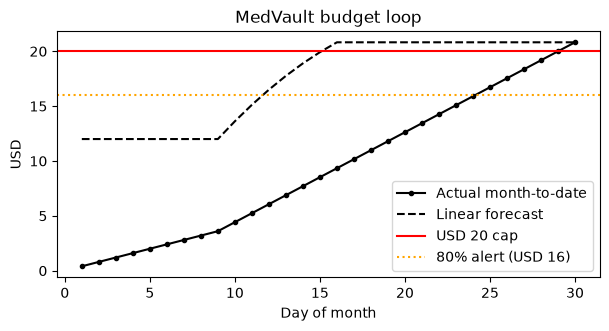

In [7]:
import matplotlib.pyplot as plt
b=pd.read_csv('results/budget_trace.csv'); display(b)
CAP=20.0
plt.figure(figsize=(7,3.2))
plt.plot(b.day,b.month_to_date_usd,'k-o',ms=3,label='Actual month-to-date')
plt.plot(b.day,b.linear_forecast_usd,'k--',label='Linear forecast')
plt.axhline(CAP,color='r',label='USD 20 cap'); plt.axhline(0.8*CAP,color='orange',ls=':',label='80% alert (USD 16)')
plt.xlabel('Day of month'); plt.ylabel('USD'); plt.legend(); plt.title('MedVault budget loop'); plt.show()

Console budget pushes (paper Table 5): start spend USD 6.96, +USD 1.60 per push, USD 20 cap, alert at 80%.

In [8]:
spend=6.96; rows=[]
for p in range(1,7):
    spend=round(spend+1.60,2); rows.append(dict(push=p,spend_usd=spend,pct_of_cap=round(100*spend/20,1),alert=spend>=16))
display(pd.DataFrame(rows))

,push,spend_usd,pct_of_cap,alert
0,1,8.56,42.8,False
1,2,10.16,50.8,False
2,3,11.76,58.8,False
3,4,13.36,66.8,False
4,5,14.96,74.8,False
5,6,16.56,82.8,True


## 5. Figures

figs/fig_budget.png


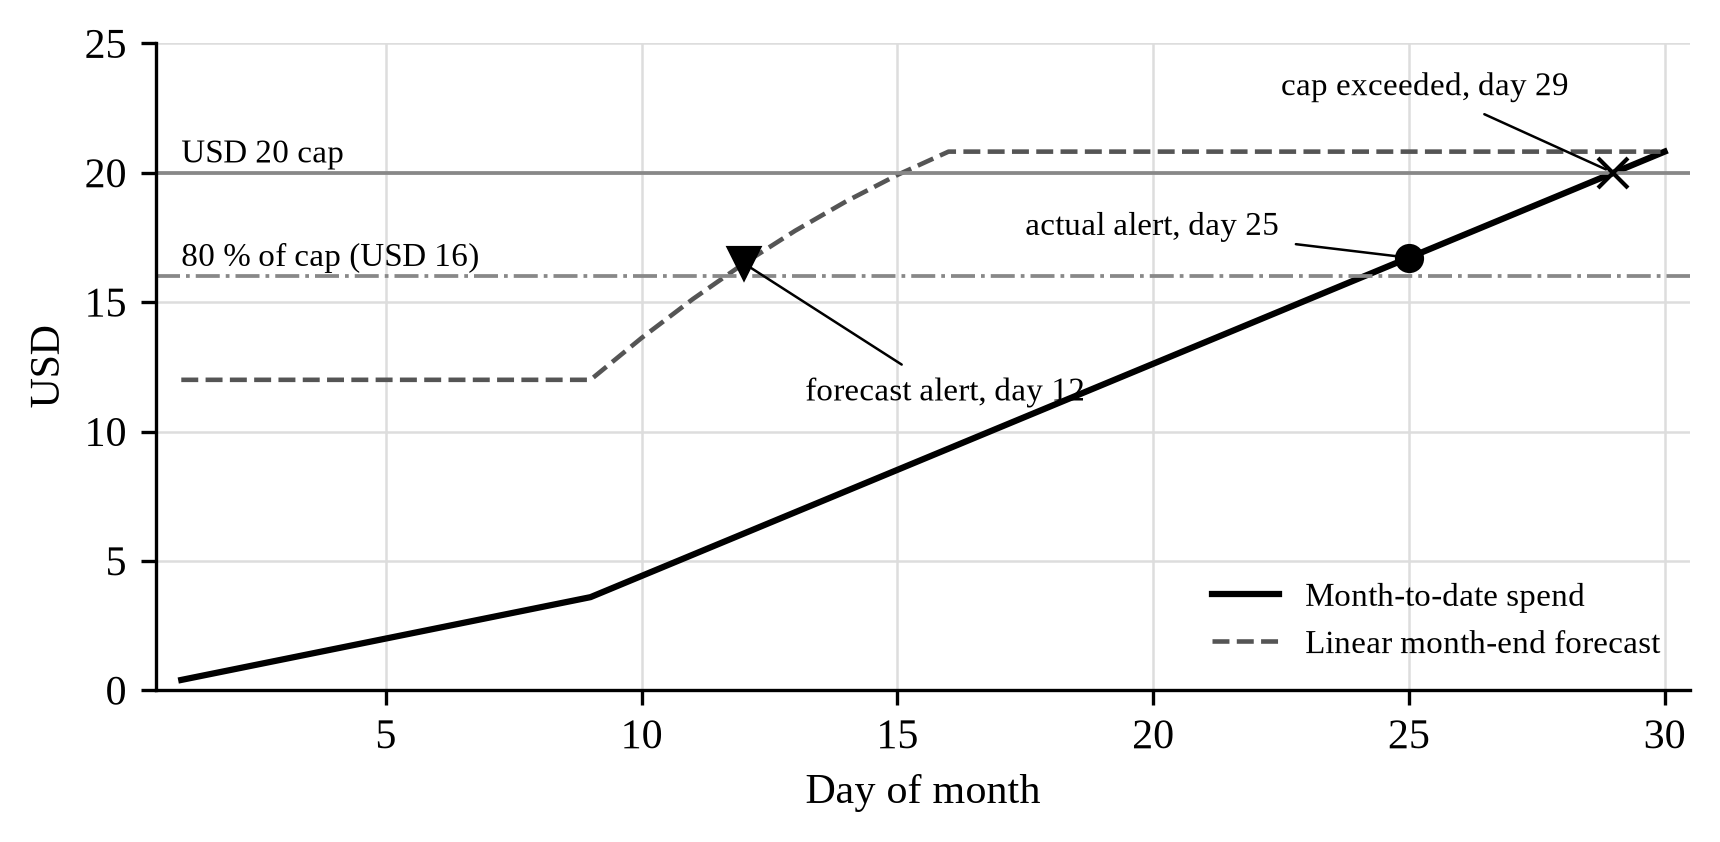

figs/fig_enforcement.png


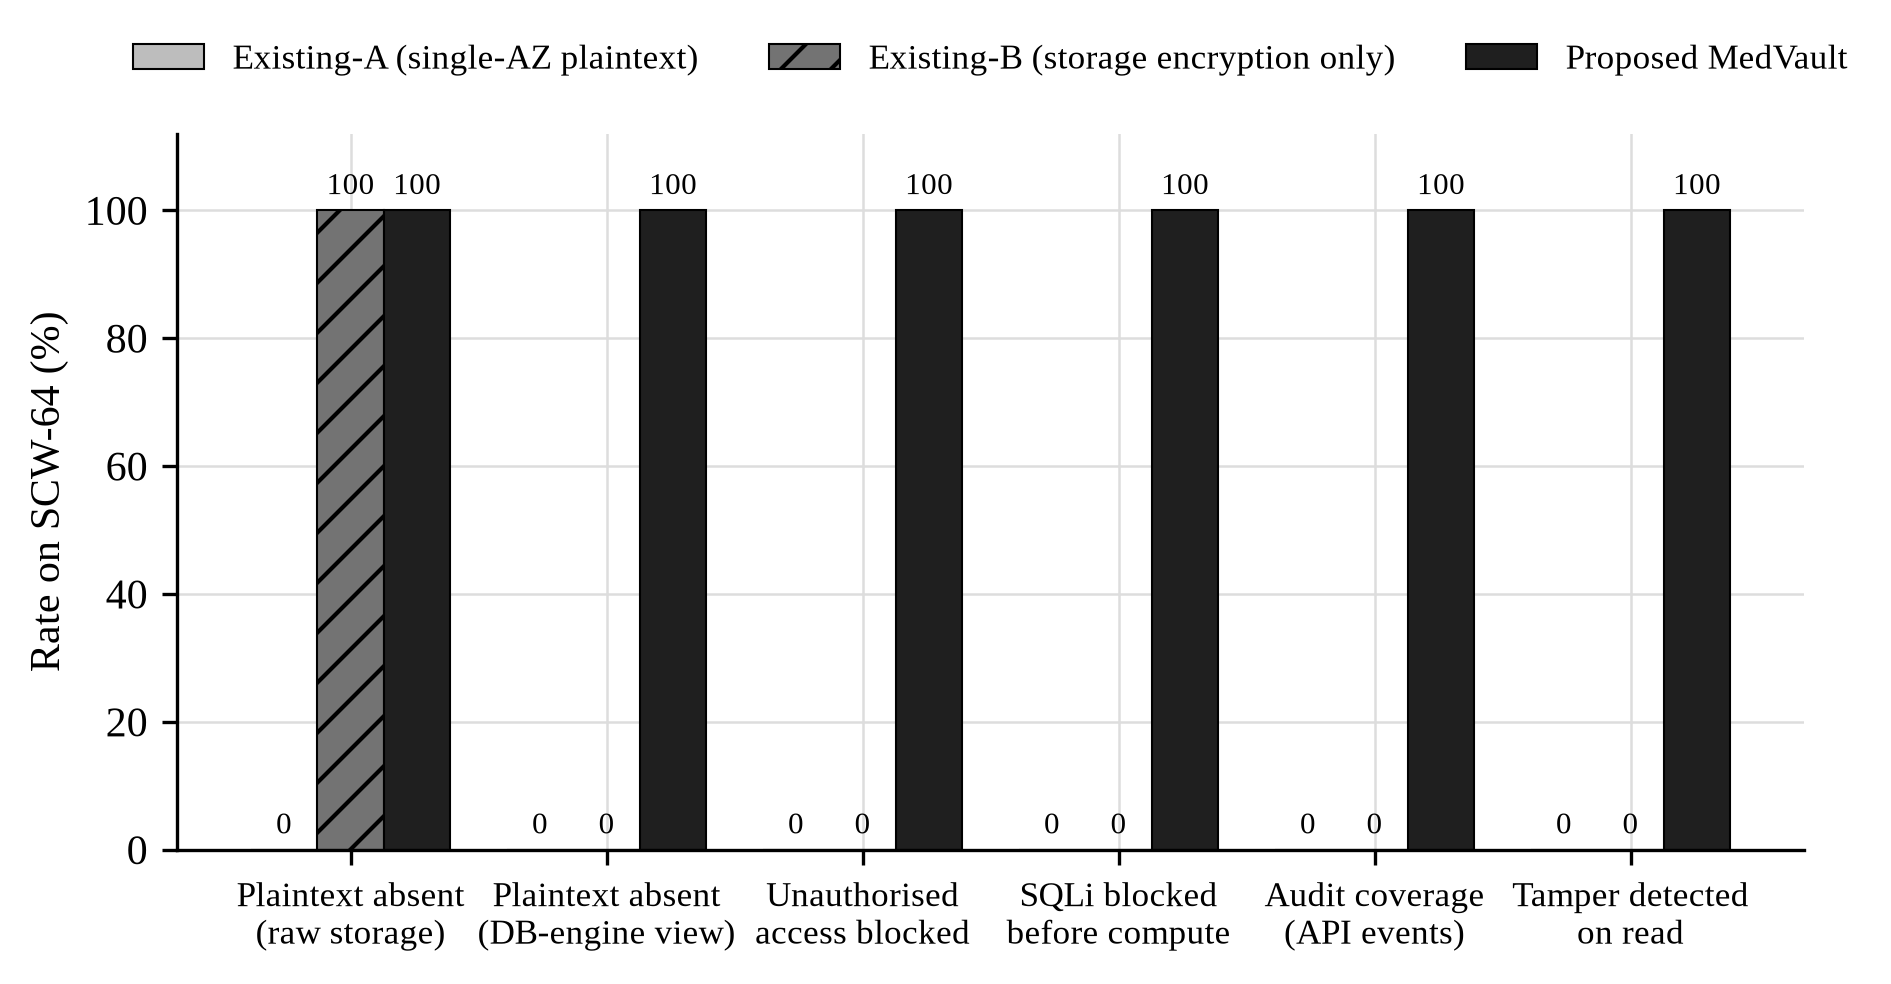

figs/fig_failover.png


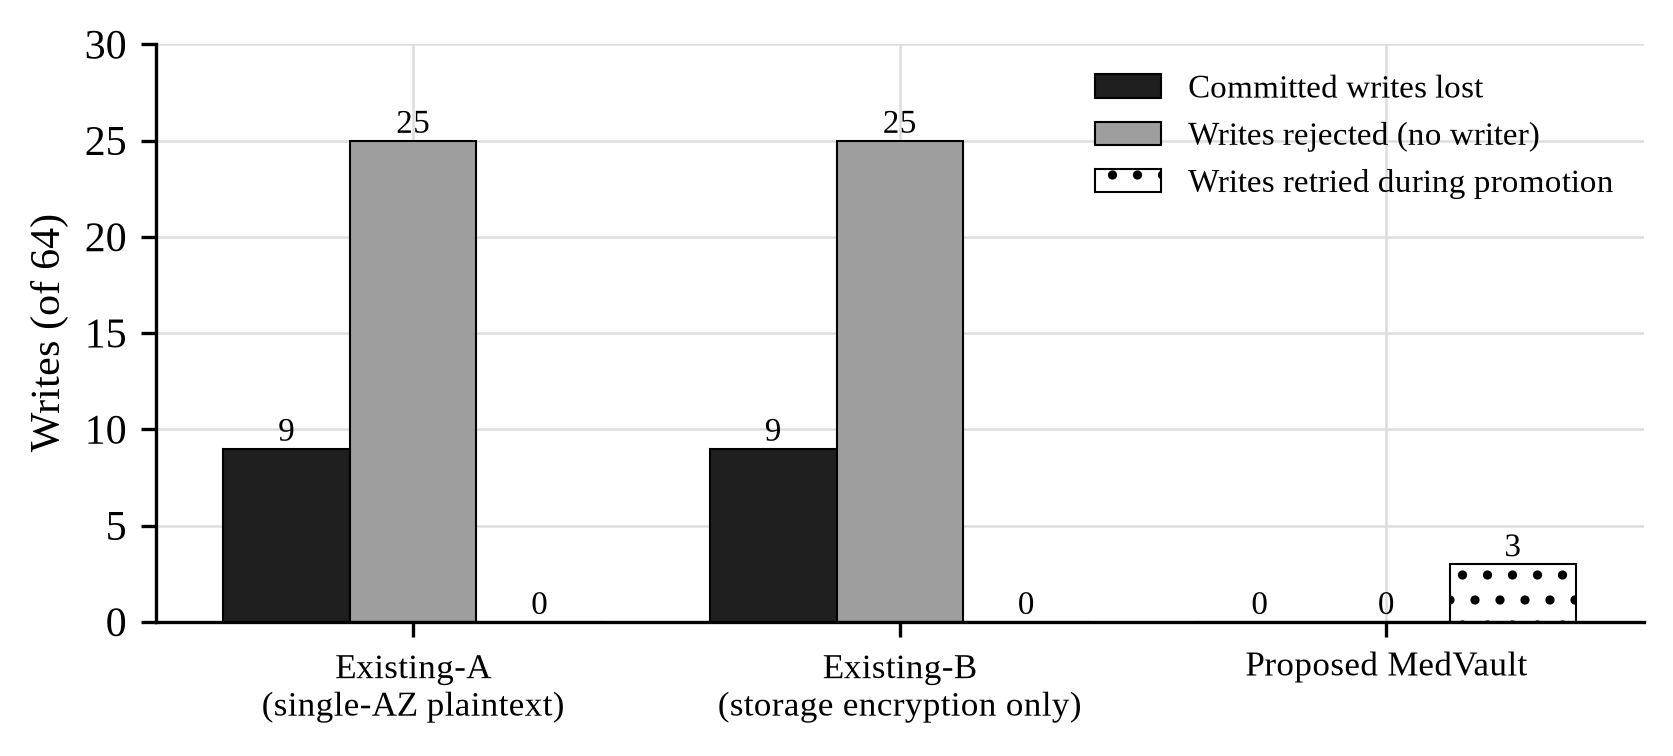

figs/fig_latency.png


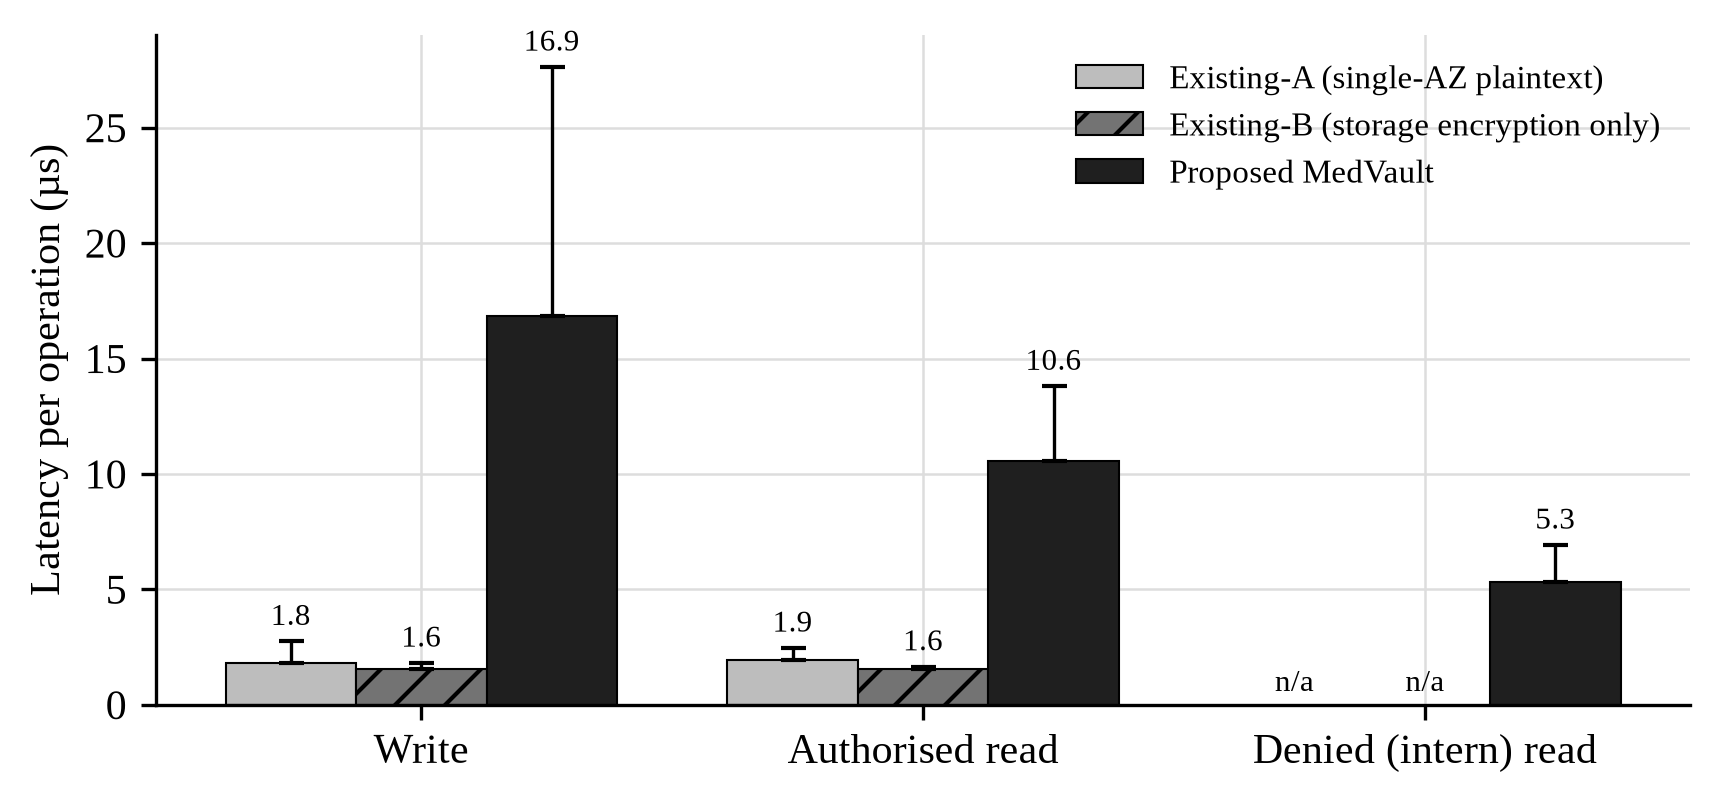

figs/fig_latency_cdf.png


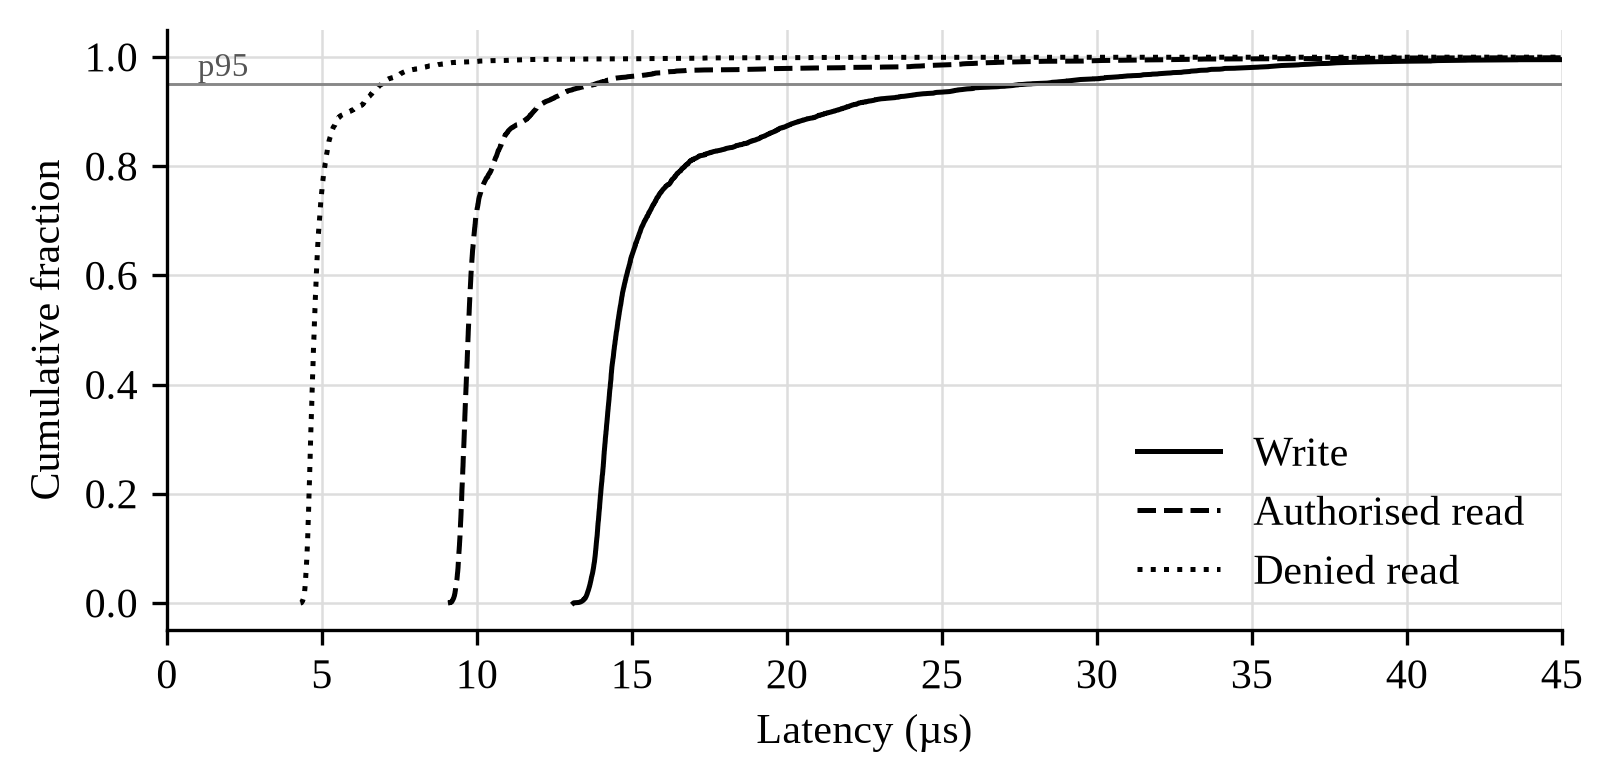

figs/fig_write_breakdown.png


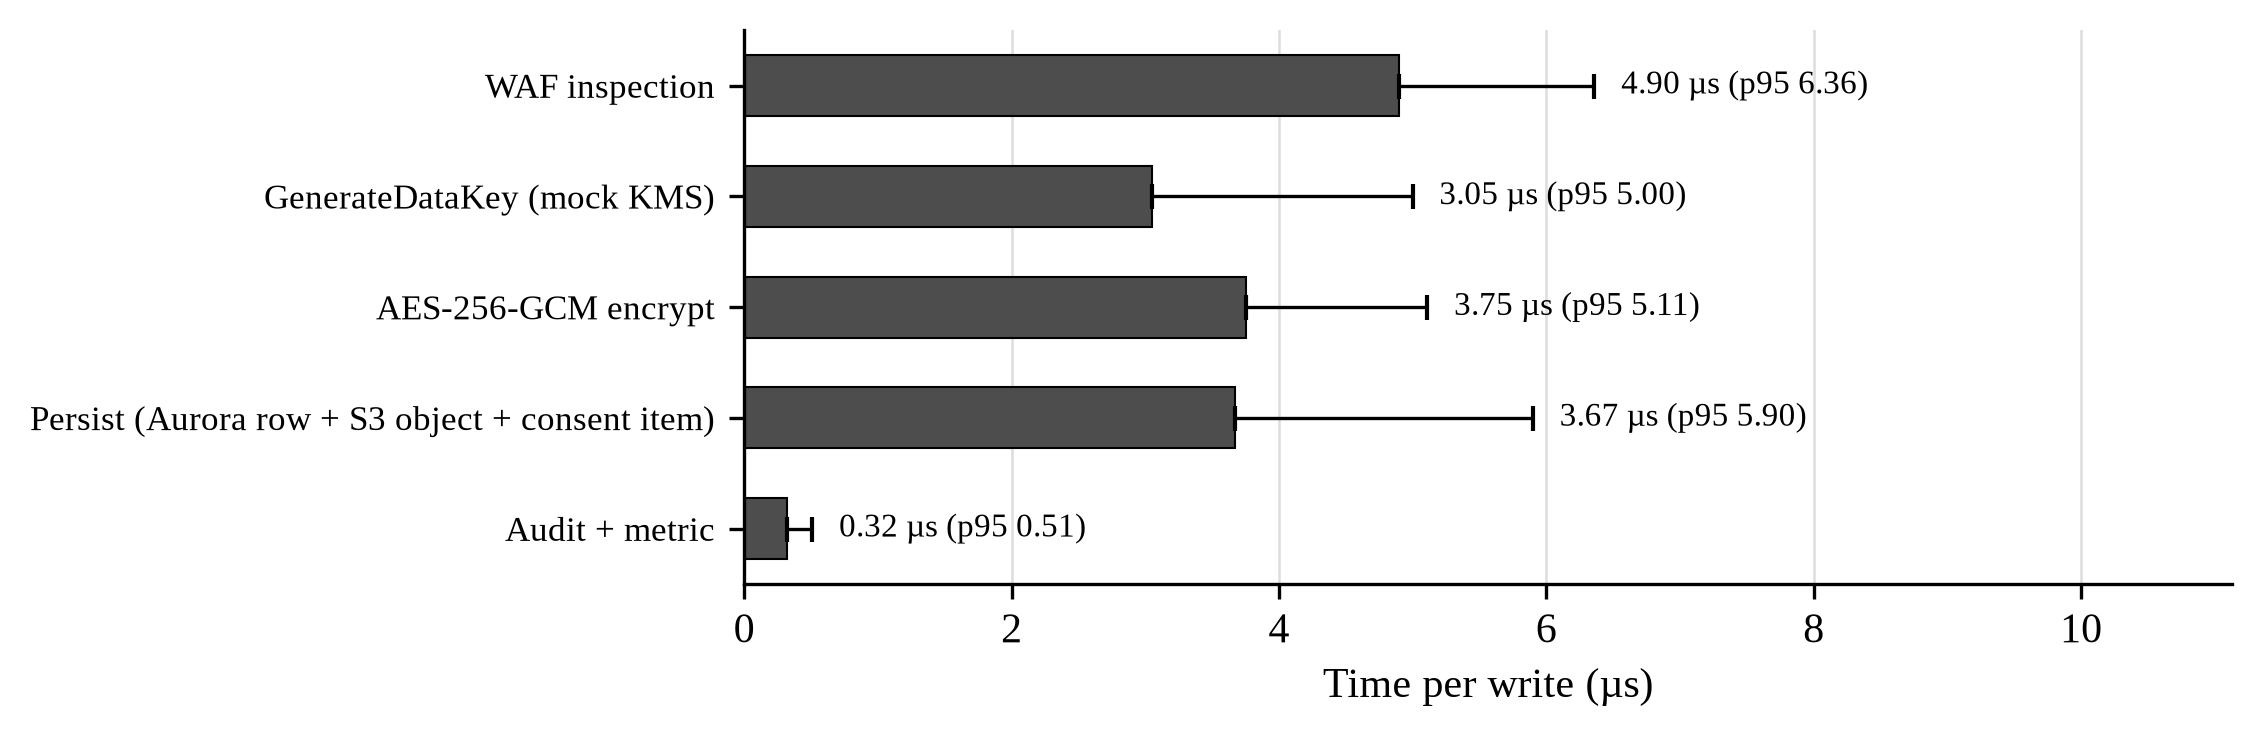

In [9]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('figs/*.png')): print(f); display(Image(f, width=650))

## 6. Envelope-encryption and key-policy demo (the Module 3 logic, simplified)

In [10]:
import os
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.exceptions import InvalidTag
CMK=AESGCM.generate_key(256)                       # stands in for the KMS customer-managed key
POLICY={'clinician-readwrite':{'Encrypt','Decrypt'},'auditor-readonly':set(),'random-intern':set()}
def kms(op,role,data,nonce=None):
    if op not in POLICY.get(role,set()): raise PermissionError(f'KMS {op} denied for {role}')
    g=AESGCM(CMK)
    if op=='Encrypt': n=os.urandom(12); return n,g.encrypt(n,data,b'edk')
    return g.decrypt(nonce,data,b'edk')
def put(role,note):
    dk=AESGCM.generate_key(256); n=os.urandom(12)
    ct=AESGCM(dk).encrypt(n,note.encode(),b'enc-1')
    en,edk=kms('Encrypt',role,dk); return dict(nonce=n,ct=ct,edk_nonce=en,edk=edk)
def get(role,rec):
    dk=kms('Decrypt',role,rec['edk'],rec['edk_nonce']); return AESGCM(dk).decrypt(rec['nonce'],rec['ct'],b'enc-1').decode()
rec=put('clinician-readwrite','Synthetic note: BP 120/80, follow-up 2 weeks')
print('stored row (no plaintext):',{k:v.hex()[:24]+'...' for k,v in rec.items()})
print('clinician read ->',get('clinician-readwrite',rec))
for r in ['random-intern','auditor-readonly']:
    try: get(r,rec)
    except PermissionError as e: print('denied:',e)
bad=dict(rec); bad['ct']=bytes([rec['ct'][0]^1])+rec['ct'][1:]
try: get('clinician-readwrite',bad)
except InvalidTag: print('tampered ciphertext detected on read (GCM tag mismatch)')

stored row (no plaintext): {'nonce': 'a3e91b16d94da1fa23696145...', 'ct': 'bec86d1da31ab2959016ac3c...', 'edk_nonce': '6c93cc670d734153f170093e...', 'edk': '1fe36bac167bcf8a75ec3b6b...'}
clinician read -> Synthetic note: BP 120/80, follow-up 2 weeks
denied: KMS Decrypt denied for random-intern
denied: KMS Decrypt denied for auditor-readonly
tampered ciphertext detected on read (GCM tag mismatch)


Demo console: https://rawcdn.githack.com/notnoob445/medvault-demo/d8ef194871d39ddb6a1b0383756dd3a515059b01/index.html (static HTML, also included as `index.html`).